# Olist — слой Gold

Gold — слой для анализа: схема «звезда» из измерений и таблиц фактов и готовые витрины поверх неё.
Ноутбук проверяет, что модель согласована, и показывает, от каких ошибок она защищает.

**Данные:** `data/gold/olist/core/` и `data/gold/olist/marts/`, отчёт `_validation.json`, созданные скриптами
`gold_core` и `gold_marts`. Модель — в [olist_star_schema.md](../../../docs/data_models/olist_star_schema.md),
описание слоя — в [gold.md](../../../docs/architecture/gold.md).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analytics.db import q
from src.analytics import style as st

st.apply_style()
pd.set_option("display.float_format", lambda v: st.num(v, 2))
pd.set_option("display.max_columns", 30)

In [2]:
import json

from src.analytics.db import tables
from src.utils.config import GOLD_DIR

validation = json.loads((GOLD_DIR / "olist" / "core" / "_validation.json").read_text(encoding="utf-8"))
validation["status"], validation["errors"]

('OK', [])

## Схема «звезда»

**Вопрос:** из каких таблиц состоит модель и какова гранулярность каждой?

In [3]:
grain = {
    "dim_date": "день", "dim_geography": "почтовый индекс", "dim_product": "товар", "dim_seller": "продавец",
    "dim_customer": "покупатель (человек)", "fact_orders": "заказ", "fact_order_items": "товарная позиция",
    "fact_payments": "платёж", "fact_reviews": "связь «отзыв ↔ заказ»",
}
model = pd.DataFrame([{"таблица": name, "тип": "факт" if name.startswith("fact") else "измерение",
                       "гранулярность": grain[name], "строк": t["rows"]}
                      for name, t in validation["tables"].items()])
model

,таблица,тип,гранулярность,строк
0,dim_date,измерение,день,852
1,dim_geography,измерение,почтовый индекс,19011
2,dim_product,измерение,товар,32951
3,dim_seller,измерение,продавец,3095
4,fact_orders,факт,заказ,99441
5,dim_customer,измерение,покупатель (человек),96096
6,fact_order_items,факт,товарная позиция,112650
7,fact_payments,факт,платёж,103886
8,fact_reviews,факт,связь «отзыв ↔ заказ»,99224


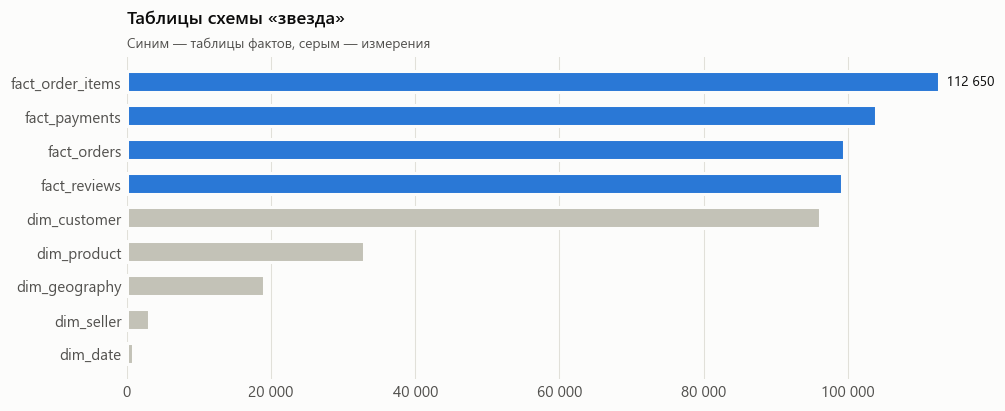

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.8))
order = model.sort_values("строк", ascending=False)
st.hbar(ax, order["таблица"], order["строк"], highlight=[n for n in order["таблица"] if n.startswith("fact")], fmt=st.num)
st.count_axis(ax, "x")
st.titles(ax, "Таблицы схемы «звезда»", "Синим — таблицы фактов, серым — измерения")
st.save(fig, "olist_gold_01_star_schema_tables")
plt.show()

**Вывод.** Модель состоит из 4 таблиц фактов с разной гранулярностью (заказ, позиция, платёж, отзыв)
и 5 измерений (дата, география, товар, продавец, покупатель). Измерение покупателей меньше заказов:
96 096 людей на 99 441 заказ, потому что ключ покупателя — `customer_unique_id`.

## Проверки целостности

**Вопрос:** сходятся ли таблицы фактов между собой и с Silver?

In [5]:
pd.DataFrame(validation["reconciliation"]).rename(columns={"check": "проверка", "left": "слева", "right": "справа", "ok": "совпадает"})

,проверка,слева,справа,совпадает
0,fact_orders rows = silver orders,99441,99441,True
1,fact_order_items rows = silver order_items,112650,112650,True
2,fact_payments rows = silver payments,103886,103886,True
3,fact_reviews rows = silver reviews,99224,99224,True
4,dim_customer rows = distinct customer_unique_id,96096,96096,True
5,sum(items.price) = sum(orders.items_value),13591643.70,13591643.70,True
6,sum(items.freight) = sum(orders.freight_value),2251909.54,2251909.54,True
7,sum(payments.value) = sum(orders.payment_value),16008872.12,16008872.12,True
8,latest reviews = orders with review,98673,98673,True


In [6]:
fk = pd.DataFrame(validation["foreign_keys"])
pd.DataFrame({"проверено связей": [len(fk)], "пустых ссылок": [int(fk.nulls.sum())], "висячих ссылок": [int(fk.orphans.sum())]})

,проверено связей,пустых ссылок,висячих ссылок
0,17,0,0


**Вывод.** Все 9 сверок совпадают до копейки: число строк фактов равно Silver, суммы цен, доставки и платежей
одинаковы в позициях, платежах и заказах, у каждого заказа с отзывом ровно один последний отзыв.
17 внешних ключей без единой пустой или висячей ссылки.

## Почему факты разделены: размножение строк

**Вопрос:** что будет, если соединить товарные позиции с платежами и отзывами в одном запросе?

In [7]:
example = q("""
    select o.order_id, o.items_count, o.payments_count
    from fact_orders o
    where o.is_valid_order and o.items_count = 2 and o.payments_count = 2
    order by o.order_id
    limit 1
""")
example_id = example.order_id[0]
q(f"""
    select i.order_item_id, i.price, p.payment_sequential, p.payment_type, p.payment_value
    from fact_order_items i
    join fact_payments p using (order_id)
    where order_id = '{example_id}'
    order by 1, 3
""")

,order_item_id,price,payment_sequential,payment_type,payment_value
0,1,"189,00",1,credit_card,"319,34"
1,1,"189,00",2,voucher,"56,39"
2,2,"109,90",1,credit_card,"319,34"
3,2,"109,90",2,voucher,"56,39"


In [8]:
fanout = q("""
    select 'Правильно: только позиции' as variant,
           (select sum(price) from fact_order_items where is_valid_order) as revenue,
           (select count(*) from fact_order_items where is_valid_order) as rows
    union all
    select 'Позиции × платежи',
           sum(i.price), count(*)
    from fact_order_items i join fact_payments p using (order_id)
    where i.is_valid_order
    union all
    select 'Позиции × платежи × отзывы',
           sum(i.price), count(*)
    from fact_order_items i join fact_payments p using (order_id) join fact_reviews r using (order_id)
    where i.is_valid_order
""")
fanout["завышение"] = fanout.revenue / fanout.revenue.iloc[0] - 1
st.as_pct(fanout, ["завышение"], 2)

,variant,revenue,rows,завышение
0,Правильно: только позиции,"13 494 400,74",112101,"0,00%"
1,Позиции × платежи,"14 105 767,00",117028,"4,53%"
2,Позиции × платежи × отзывы,"14 039 555,97",116769,"4,04%"


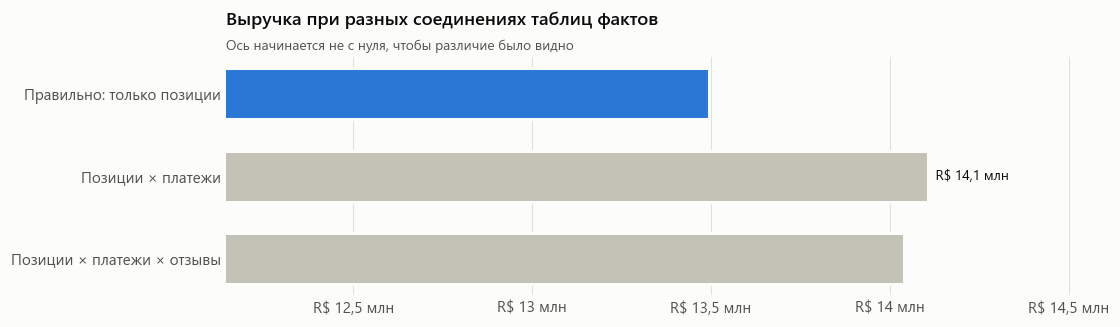

In [9]:
fig, ax = plt.subplots(figsize=(10, 2.8))
st.hbar(ax, fanout["variant"], fanout["revenue"], highlight=[fanout["variant"].iloc[0]], color=st.BLUE, fmt=st.brl)
ax.set_xlim(fanout.revenue.min() * 0.9, fanout.revenue.max() * 1.03)
st.money_axis(ax, "x")
st.titles(ax, "Выручка при разных соединениях таблиц фактов", "Ось начинается не с нуля, чтобы различие было видно")
st.save(fig, "olist_gold_02_fanout")
plt.show()

**Формула**

$$\text{строк после соединения} = \sum_{o} i_o \cdot p_o, \qquad \text{завышение} = \frac{\sum_{o} \left(p_o \sum_{k=1}^{i_o} \mathrm{price}_{o,k}\right)}{\sum_{o} \sum_{k=1}^{i_o} \mathrm{price}_{o,k}} - 1$$

где $i_o$ — число позиций заказа $o$, $p_o$ — число его платежей. Каждая позиция повторяется столько раз,
сколько у заказа платежей, и её цена попадает в сумму $p_o$ раз.

**Пример расчёта**

Заказ с 2 позициями и 2 платежами даёт $2 \cdot 2 = 4$ строки, и выручка заказа учитывается дважды.
По всем данным:

$$\frac{14\,105\,767{,}00}{13\,494\,400{,}74} - 1 \approx 0{,}045 \;(+4{,}5\%)$$

**Вывод.**
- Прямое соединение позиций с платежами завышает выручку на 4,5% (R&#36; 611 тыс.), хотя запрос
  выглядит правильно и не выдаёт ошибок.
- С отзывами завышение «уменьшается» до 4,0%, но это не исправление, а две ошибки сразу: внутреннее
  соединение выбрасывает заказы без отзыва и одновременно дублирует заказы с несколькими отзывами.
  Ошибки частично гасят друг друга, и сумма случайно оказывается ближе к правильной.
- Поэтому в модели у каждой гранулярности своя таблица фактов, а `fact_orders` хранит уже агрегированные
  показатели заказа: выручку, доставку, сумму платежей, последнюю оценку. Большинство вопросов решается
  одной таблицей без соединений фактов между собой.

## Покупка и заказ: разбитый чекаут

**Вопрос:** почему повторную покупку нельзя считать по числу заказов?

In [10]:
split = q("""
    select customer_key, purchase_ts, count(*) as orders, count(distinct order_id) as distinct_orders,
           list(order_id order by order_id) as order_ids, max(customer_purchase_seq) as purchase_seq
    from fact_orders
    where is_valid_order
    group by 1, 2
    having count(*) > 1
    order by orders desc, customer_key
""")
print(f"Чекаутов из нескольких заказов: {st.num(len(split))}, заказов в них: {st.num(split.orders.sum())}")
split.head(3)

Чекаутов из нескольких заказов: 281, заказов в них: 564


,customer_key,purchase_ts,orders,distinct_orders,order_ids,purchase_seq
0,66980c3775537536f77b434d74e520f5,2018-03-31 15:08:21,3,3,"[41c284ffd871324eadf06fc989583619, 8e17072ec97...",1
1,e13e8b789e5a8e6fe1445f924a4ed4f6,2018-06-01 13:39:44,3,3,"[97f95535ada31d6fa853230e815ee4e3, cd0343141ac...",1
2,02b20b7c813efede140142ac610e36dc,2018-03-19 20:50:39,2,2,"[25ce3a22fa2537206c22c8bef4f9b593, 62ec63f37c8...",1


In [11]:
rpr = q("""
    select avg((orders_count >= 2)::int)            as by_orders,
           avg((purchase_occasions_count >= 2)::int) as by_purchases,
           sum((orders_count >= 2)::int)::bigint             as customers_by_orders,
           sum((purchase_occasions_count >= 2)::int)::bigint as customers_by_purchases
    from dim_customer
    where orders_count > 0
""")
st.as_pct(rpr, ["by_orders", "by_purchases"], 2)

,by_orders,by_purchases,customers_by_orders,customers_by_purchases
0,"3,04%","2,78%",2888,2638


**Формула**

$$\mathrm{seq}_o = \operatorname{dense\_rank}\left(t^{\mathrm{purch}}_o\right) \text{ внутри покупателя}, \qquad P_c = \max_{o \in c} \mathrm{seq}_o$$

где заказы одного покупателя с одинаковым моментом покупки получают одинаковый номер $\mathrm{seq}$,
а $P_c$ — число разных покупок.

**Пример расчёта**

$$\mathrm{RPR}_{\text{заказы}} = \frac{2\,888}{94\,990} \approx 0{,}0304, \qquad \mathrm{RPR}_{\text{покупки}} = \frac{2\,638}{94\,990} \approx 0{,}0278, \qquad \frac{0{,}0304}{0{,}0278} - 1 \approx 0{,}09$$

**Вывод.**
- Когда покупатель берёт в одной корзине товары разных продавцов, Olist создаёт отдельный заказ на каждого
  продавца с одинаковым временем покупки.
- Если считать по заказам, такой покупатель выглядит «повторным», и доля повторных покупателей
  завышается примерно на 9%. В модели номер покупки `customer_purchase_seq` считается через
  `dense_rank` по времени, и заказы одного чекаута получают один номер.

## Элементы «неизвестно»

**Вопрос:** сколько строк не нашли пару в измерении и что с ними происходит?

In [12]:
unknown = q("""
    select 'заказы с неизвестной географией' as what,
           sum((delivery_geo_key = 'unknown')::int)::bigint as rows, count(*) as total
    from fact_orders
    union all
    select 'продавцы с неизвестной географией', sum((geo_key = 'unknown')::int)::bigint, count(*) from dim_seller
    union all
    select 'товары с неизвестной категорией', sum((category_pt = 'unknown')::int)::bigint, count(*) from dim_product
""")
unknown["доля"] = unknown.rows / unknown.total
st.as_pct(unknown, ["доля"], 2)

,what,rows,total,доля
0,заказы с неизвестной географией,279,99441,"0,28%"
1,продавцы с неизвестной географией,7,3095,"0,23%"
2,товары с неизвестной категорией,610,32951,"1,85%"


**Вывод.** Вместо пустых внешних ключей в измерениях есть строки `unknown`. Поэтому обычное соединение
никогда не теряет факты: 0,28% заказов без координат индекса всё равно попадают в выручку по штату
(штат покупателя известен всегда), а 610 товаров без категории — в категорию `unknown`.

## Витрины

**Вопрос:** сходится ли выручка во всех витринах, построенных из одной модели?

In [13]:
marts = q("""
    select 'gold_sales_daily' as mart, sum(revenue) as revenue from gold_sales_daily
    union all select 'gold_sales_category', sum(revenue) from gold_sales_category
    union all select 'gold_customer_metrics', sum(revenue) from gold_customer_metrics
    union all select 'gold_product_metrics', sum(revenue) from gold_product_metrics
    union all select 'gold_rfm_segments', sum(monetary) from gold_rfm_segments
""")
marts["отклонение от fact_orders"] = marts.revenue - q("select sum(items_value) as r from fact_orders where is_valid_order").r[0]
marts

,mart,revenue,отклонение от fact_orders
0,gold_sales_daily,"13 494 400,74","0,00"
1,gold_sales_category,"13 494 400,74","0,00"
2,gold_customer_metrics,"13 494 400,74","0,00"
3,gold_product_metrics,"13 494 400,74","0,00"
4,gold_rfm_segments,"13 494 400,74","0,00"


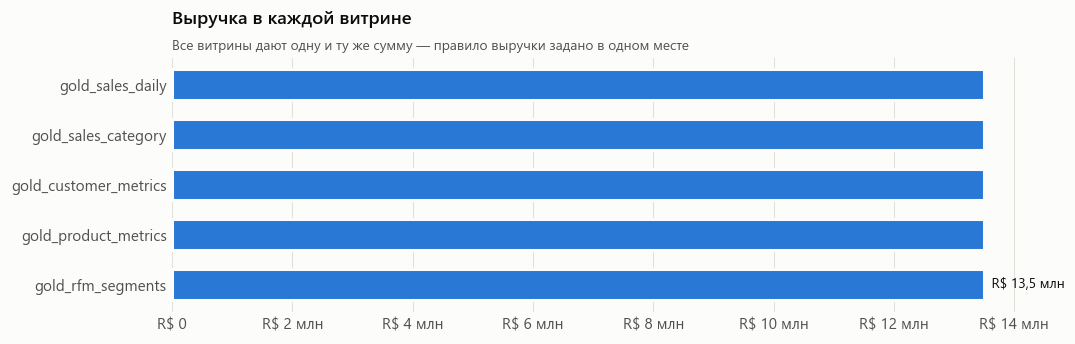

In [14]:
fig, ax = plt.subplots(figsize=(10, 3))
st.hbar(ax, marts["mart"], marts["revenue"], fmt=st.brl)
st.money_axis(ax, "x")
st.titles(ax, "Выручка в каждой витрине", "Все витрины дают одну и ту же сумму — правило выручки задано в одном месте")
st.save(fig, "olist_gold_03_marts_revenue")
plt.show()

**Вывод.** Пять витрин с разной гранулярностью (день, месяц × категория, покупатель, товар, RFM-сегмент)
дают одну и ту же выручку — R&#36; 13 494 400,74, отклонение 0. Правило «валидный заказ, только товары,
без доставки» задано один раз в таблицах фактов, и витрины не могут считать выручку по-разному.

## Итоги

| Проверка | Результат |
|---|---|
| Модель | 4 таблицы фактов и 5 измерений с явной гранулярностью |
| Сверки | 9 из 9 совпадают до копейки, 17 внешних ключей без ошибок |
| Размножение строк | прямое соединение позиций и платежей завысило бы выручку на 4,5% |
| Разбитые чекауты | номер покупки по времени убирает завышение доли повторных покупателей на 9% |
| Неизвестные значения | строки `unknown` вместо пустых ключей, факты не теряются |
| Витрины | одна и та же выручка во всех пяти витринах |

Дальше эта модель используется в аналитических ноутбуках `../01_sales_analytics.ipynb` … `../04_logistics_analytics.ipynb`.